# HW4: stock-return model and backtest

Ananya Das. This notebook walks through the development work. The code is in `hw4.py` in this folder; see `README.md` for how to run everything and for the write-up.

**Final test:** run once on 2026-11-16 with the frozen settings (`python hw4.py final`); results are in `final_results.md` and shown in section 5. This notebook itself loads nothing after 2016-03-31.

In [1]:
import pandas as pd
from IPython.display import Image, display

import hw4

pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:,.4f}'.format)
print('Final test switch:', hw4.RUN_FINAL_TEST, '| data limit:', hw4.BUFFER_END.date())

Final test switch: False | data limit: 2016-03-31


## 1. Data, features, validation, and the development backtest

`hw4.develop()` loads the full database through Mar 31, 2016 and then:
- builds month-end features and 90-day targets for 2010–2015;
- runs the walk-forward validation;
- fits the yearly models;
- runs the 2012–2015 backtest at 5, 10, and 20 bps;
- audits the accounting.

It takes about 30 seconds.

In [2]:
r = hw4.develop()
print(f'{len(r.panel):,} panel rows on {len(r.dates)} month-ends; '
      f'{r.panel.groupby("date").size().median():.0f} eligible stocks per date (median)')
r.panel[hw4.FEATURES + ['target', 'excess_w']].describe().T[['count', 'mean', '50%', 'min', 'max']]

/Users/ananya/Documents/UCB-MFE-python-preprogram-2026-winter/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


133,839 panel rows on 72 month-ends; 1861 eligible stocks per date (median)


,count,mean,50%,min,max
mom_21,"133,837.0000",0.5003,0.5003,0.0005,1.0000
mom_252_21,"129,624.0000",0.5003,0.5003,0.0005,1.0000
vol_63,"133,733.0000",0.5003,0.5003,0.0005,1.0000
drawdown_252,"129,838.0000",0.5003,0.5003,0.0005,0.9987
operating_roa,"133,800.0000",0.5003,0.5003,0.0005,1.0000
accruals_to_assets,"133,756.0000",0.5003,0.5003,0.0005,1.0000
debt_to_assets,"133,800.0000",0.5003,0.5003,0.0569,1.0000
log_cap,"133,839.0000",0.5003,0.5003,0.0005,1.0000
target,"131,853.0000",0.0330,0.0281,-0.9595,22.7037
excess_w,"131,853.0000",0.0025,0.0000,-0.6071,0.8035


Features are percentile ranks within each date, so the raw scale (and the bad prints in the raw data) don't matter. The raw `target` still has a bad-print maximum, which is why the training target `excess_w` is capped at each date's 1st/99th percentiles.

## 2. Walk-forward validation

Each year's model is fit at that year's first session, on targets that had already ended, then scored on the year's month-ends. The alpha grid was fixed in advance.

In [3]:
display(r.by_alpha)
print('chosen alpha:', f'{r.alpha:,.0f}')
r.wf[r.wf.alpha.eq(r.alpha)][['year', 'fit_date', 'n_train', 'rank_IC', 'decile_spread']]

,rank_IC,decile_spread,IC_hit_rate
alpha,,,
10,0.0428,0.0227,0.7879
1000,0.0444,0.0239,0.7879
100000,0.0599,0.0314,0.6818
10000000,0.0615,0.0317,0.6610


chosen alpha: 10,000,000


,year,fit_date,n_train,rank_IC,decile_spread
3,2012,2012-01-03,34830,0.0694,0.0433
7,2013,2013-01-02,58264,-0.0356,-0.0372
11,2014,2014-01-02,80905,0.0995,0.0405
15,2015,2015-01-02,104332,0.1127,0.0801


What the model ended up liking (weights are each coefficient / sum of |coefficients|):

In [4]:
(r.weights * 100).round(1).astype(str) + '%'

,fit 2011-12-30,fit 2012-01-03,fit 2013-01-02,fit 2014-01-02,fit 2015-01-02
mom_21,-0.3%,-0.3%,-3.3%,-1.7%,-5.3%
mom_252_21,8.7%,8.7%,12.1%,22.4%,15.2%
vol_63,-20.7%,-20.7%,-15.8%,-5.3%,-11.3%
drawdown_252,13.7%,13.7%,9.4%,9.2%,8.5%
operating_roa,35.2%,35.2%,28.6%,37.8%,32.7%
accruals_to_assets,-1.7%,-1.7%,3.7%,0.9%,0.7%
debt_to_assets,5.5%,5.5%,15.6%,17.3%,17.7%
log_cap,14.3%,14.3%,11.6%,5.5%,8.5%


## 3. Development backtest (Jan 2012 – Mar 2016)

This period was also used to pick alpha, so it isn't out-of-sample. The final test is.

In [5]:
r.table.loc[['final_value', 'CAGR', 'max_drawdown', 'annualized_volatility', 'Sharpe']]

,Strategy,^SP500TR buy-and-hold,Strategy minus benchmark
final_value,"1,697,251.9563","1,766,607.3709","-69,355.4147"
CAGR,0.1325,0.1432,-0.0107
max_drawdown,-0.1139,-0.1296,0.0156
annualized_volatility,0.1230,0.1315,-0.0085
Sharpe,0.9169,0.9375,-0.0207


In [6]:
r.fees

,final_value,CAGR,max_drawdown,Sharpe,fees_paid
10 bps,"1,697,251.9563",0.1325,-0.1139,0.9169,"45,012.9023"
5 bps,"1,724,633.6233",0.1368,-0.1136,0.9478,"22,704.3712"
20 bps,"1,643,785.8484",0.1240,-0.1146,0.8550,"88,468.6368"


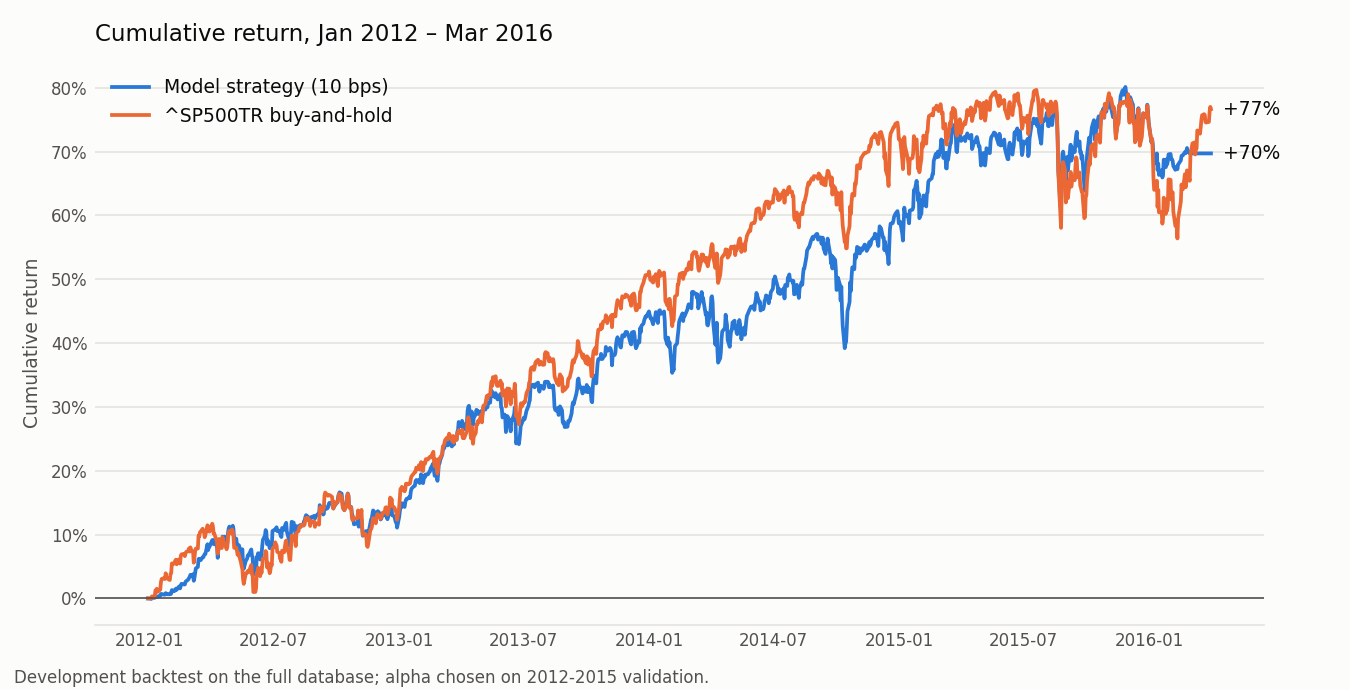

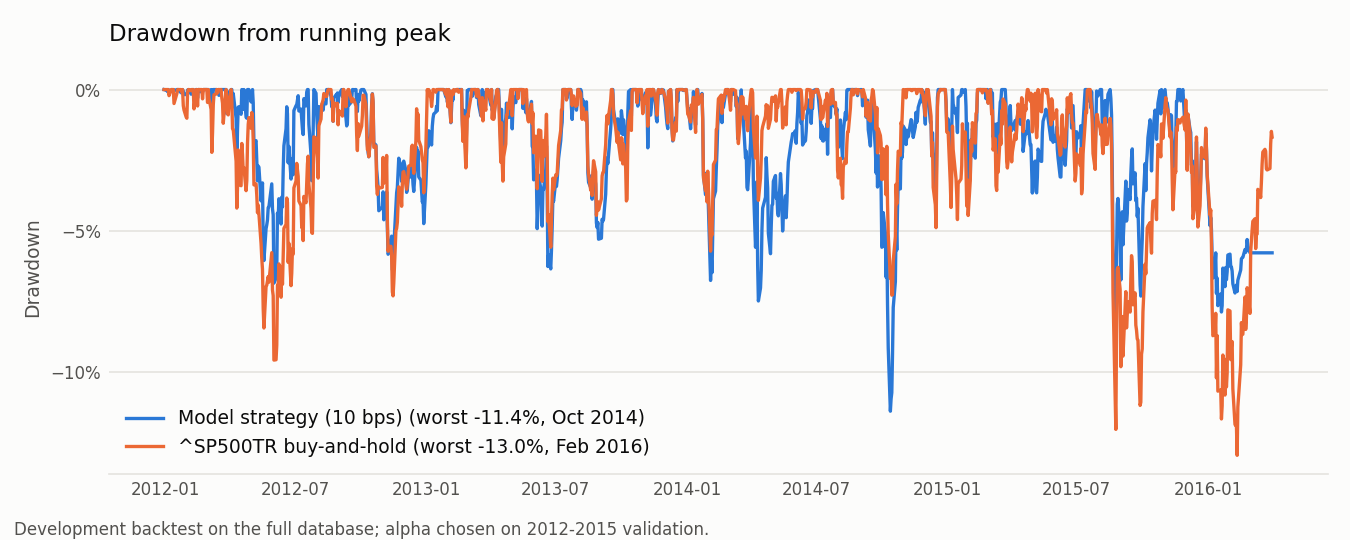

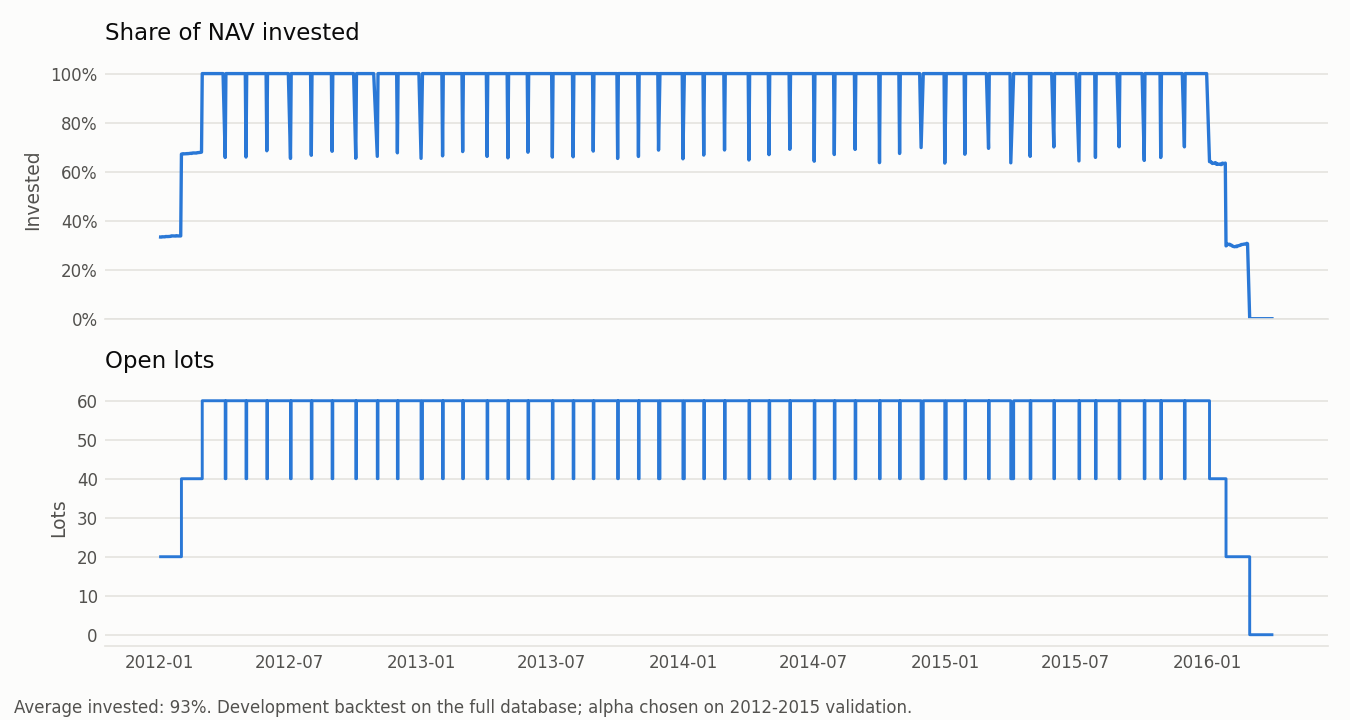

In [7]:
paths = hw4.write_report(r)
for p in paths.values():
    display(Image(filename=str(p)))

## 4. Accounting checks

Hand-checked unit tests are in `accounting_evidence.md`. These are the automatic checks on the development run's real fills:

In [8]:
r.checks

,check,detail,passed
0,"NAV = cash + holdings, every day",max gap $2.33e-10,True
1,Cash never negative,min cash $0.00,True
2,Every BUY at that day's real adjusted close,960 buys,True
3,Every BUY's signal is the previous session,signal_date vs fill date,True
4,No BUY after the last entry date,last buy 2015-12-01,True
5,Each day's buys fit in the previous close's cash,max spend/cash 1.000000,True
6,Every SELL at that day's real adjusted close,960 sells,True
7,Every SELL on/after its 90-day due date,calendar days held: 90–91,True
8,Every SELL on the first quoted session on/afte...,no early or late exits,True
9,Each lot sold at most once; buys − sells = ope...,960 − 960 = 0,True


## 5. Final test (Apr 2016 – Sep 2026)

Run once with `python hw4.py final`, using the settings frozen above. This cell only shows the saved results; it doesn't re-run anything.

# Final test results, Apr 2016 – Sep 2026

Generated by `python hw4.py final` with the settings in `frozen_config.json` (alpha 10,000,000). Models refit at: 2016-03-31, 2017-01-03, 2018-01-02, 2019-01-02, 2020-01-02, 2021-01-04, 2022-01-03, 2023-01-03, 2024-01-02, 2025-01-02, 2026-01-02.

- Loader warning: Quarantining 275 non-positive/non-finite adjusted prices.
- Loader warning: Quarantining 28 price rows not on the market calendar.

## Strategy vs $1,000,000 in ^SP500TR at the first test close

| Metric | Model strategy | ^SP500TR |
|---|---:|---:|
| start | 2016-03-31 | 2016-03-31 |
| end | 2026-09-30 | 2026-09-30 |
| final_value | $2,043,242 | $4,402,747 |
| total_return | 104.32% | 340.27% |
| CAGR | 7.04% | 15.16% |
| max_drawdown | -34.09% | -33.79% |
| annualized_volatility | 14.84% | 17.82% |
| Sharpe | 0.40 | 0.77 |

**Did not beat the benchmark by $2,359,505 in final value (-8.12% CAGR).**

If every frozen (no-quote) position were worth $0, the final value would be $1,301,042.

### Transaction-cost sensitivity

| cost per side | final value | CAGR | max drawdown | Sharpe |
|---|---:|---:|---:|---:|
| 10 bps | $2,043,242 | 7.04% | -34.09% | 0.40 |
| 5 bps | $2,120,225 | 7.42% | -34.08% | 0.42 |
| 20 bps | $1,911,284 | 6.36% | -34.11% | 0.36 |

### Accounting audit

| Check | Detail | Passed |
|---|---|:-:|
| NAV = cash + holdings, every day | max gap $2.33e-10 | ✅ |
| Cash never negative | min cash $4,864.18 | ✅ |
| Every BUY at that day's real adjusted close | 2,539 buys | ✅ |
| Every BUY's signal is the previous session | signal_date vs fill date | ✅ |
| No BUY after the last entry date | last buy 2026-09-29 | ✅ |
| Each day's buys fit in the previous close's cash | max spend/cash 0.992447 | ✅ |
| Every SELL at that day's real adjusted close | 2,450 sells | ✅ |
| Every SELL on/after its 90-day due date | calendar days held: 90–91 | ✅ |
| Every SELL on the first quoted session on/after due | no early or late exits | ✅ |
| Each lot sold at most once; buys − sells = open lots | 2539 − 2450 = 89 | ✅ |
| Open lots past due only if no quote since due | 29 open lots past due | ✅ |
| Sum of fill cash flows = final cash − initial cash | $-970,063.49 | ✅ |
| Initial capital + realized + unrealized PnL = final NAV | final NAV $2,043,241.76 | ✅ |
| No date after the run end | last date 2026-09-30 | ✅ |
| Liquidity: every BUY had ≥60 prices in the 63 sessions to its signal | min count 63 | ✅ |
| Ramp-up: exactly 3 buy days, each the first session of a month | 2016-04-01, 2016-05-02, 2016-06-01 | ✅ |
| After ramp-up: every buy day follows a sale day | 124 reinvest days | ✅ |
| After ramp-up: spend ≤ the previous close's sale proceeds | max spend/proceeds 1.000000 | ✅ |
| No held position moved beyond x4 or /4 in one day (bad-print check) | largest one-day move while held: x14.90; 6 flagged | ❌ |
| Every BUY had a raw close ≥ $5 at its signal | min $5.36 | ✅ |

**19 of 20 checks pass.** Diagnostics: 85 stale marks, 17 freezes, 1 rejected orders, 29 delayed exits. Total fees $118,694.79. Average share of NAV invested: 97.1%.



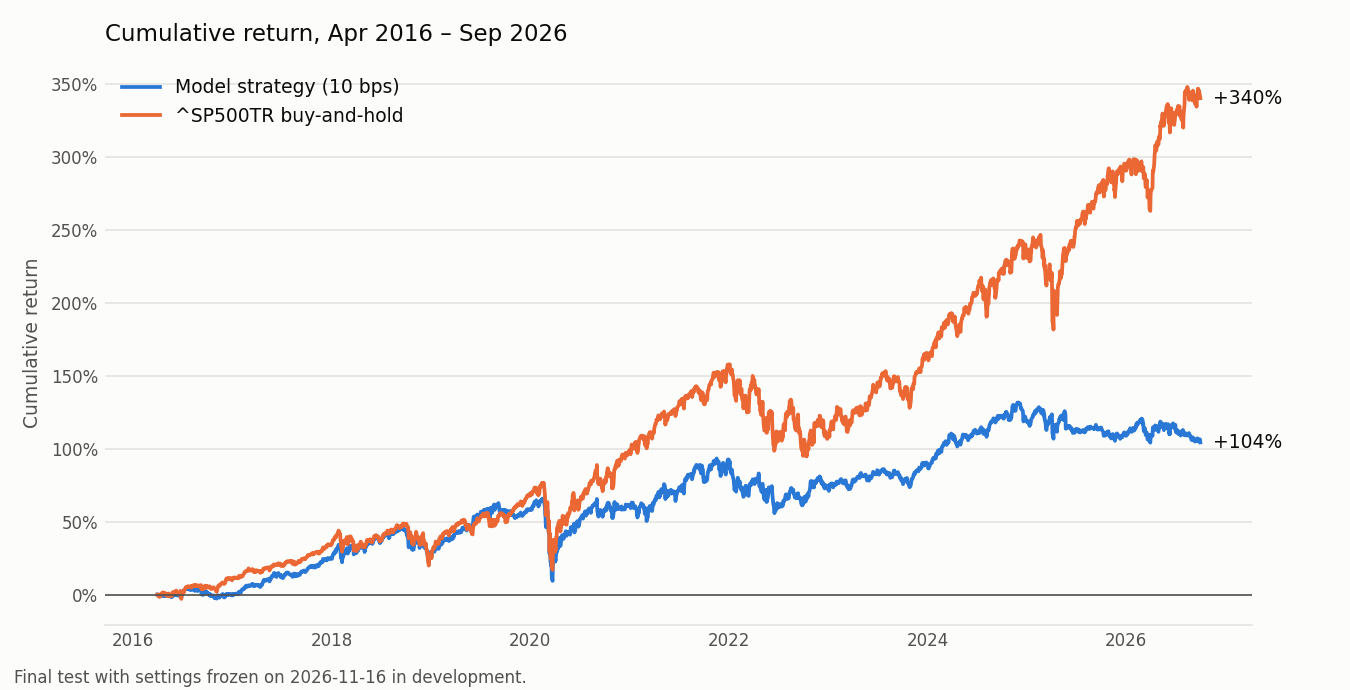

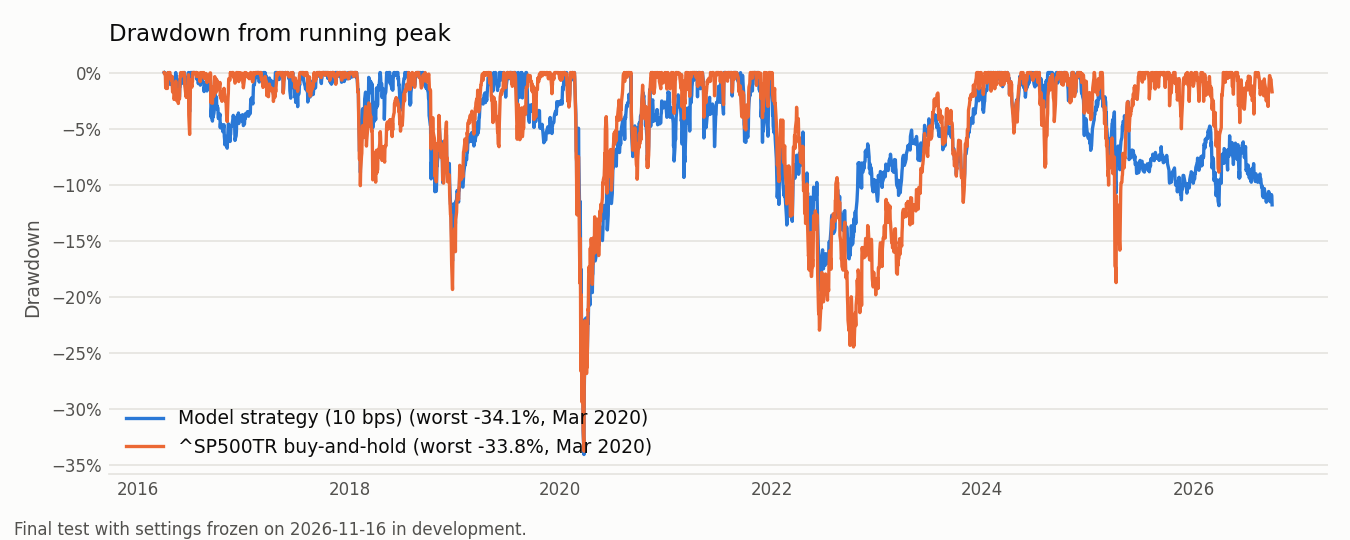

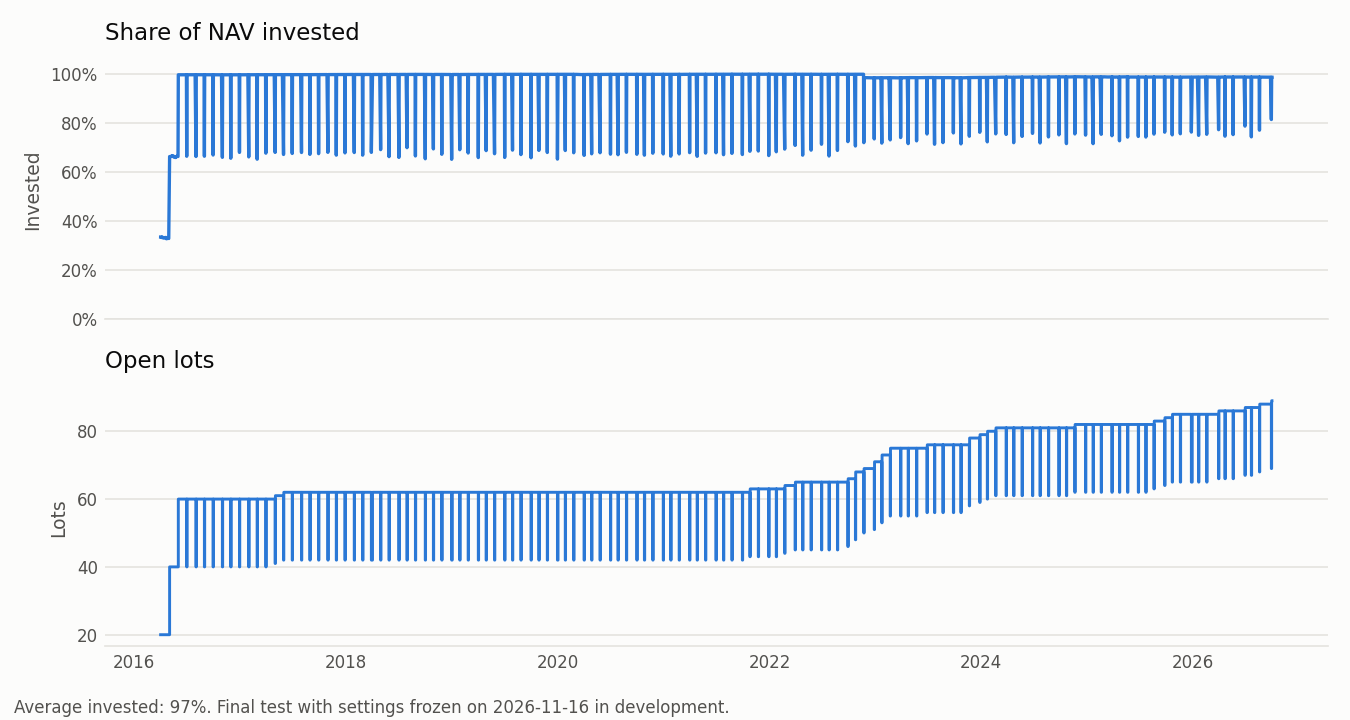

## Investigation of the failed audit check (added after the run, 2026-11-16)

The bad-print check flagged 6 positions. In every case the raw and the "adjusted" close fall by the same factor on the same day, so these are **stock splits missing from the adjusted prices**, not real losses:

| Stock | Lots | Date | Adjusted close before → after | Booked PnL |
|---|---:|---|---|---:|
| ORLY | 3 | 2025-05-23 | $1,364.79 → $91.62 (÷14.9) | −$76,665 |
| COKE | 1 | 2025-05-23 | $1,130.24 → $114.36 (÷9.9) | −$25,661 |
| KLAC | 2 | 2026-06-08 | $1,929.20 → $210.81 (÷9.2) | −$45,026 |

These 6 lots booked **−$147,352 of artificial losses**. Adding that back gives about $2.19M, still far below the benchmark's $4.40M.

**Frozen positions.** 17 stocks stopped trading while held. Most were takeovers or redemptions (LLTC 2017; SC, CDK, CHNG, SHLX, CLR, PBFX 2022; WWE, MMP 2023; TGI 2025; EA 2026; plus some preferreds and notes). The data has no deal proceeds, so these lots stay at their last price and their money is never reinvested. Frozen value grew to **$742,200 (36% of NAV) by the end** and averaged 11% of NAV over the test. If every frozen lot were worth $0, the final value would be $1,301,042. In reality most of these were cash or stock deals near the last price, so the frozen value is a reasonable mark. The larger cost is that this capital sat idle instead of being reinvested.

**Other diagnostics:** 85 stale marks, 29 delayed exits, and 1 order rejected for a missing price. The strategy was 97% invested on average (frozen lots included); 59% of its 2,450 sales made money.

Per the rules, nothing was changed or re-run after seeing these results.


In [9]:
from IPython.display import Markdown
results, investigation = open('final_results.md').read().split('## Investigation')
display(Markdown(results.split('## Plots')[0]))
for name in ['cumulative', 'drawdown', 'invested']:
    display(Image(filename=f'figures/final_{name}.png'))
display(Markdown('## Investigation' + investigation))